# CIFAR-10-C: where Ramen and NoAdapt are confused

Runs **Ramen** and the **NoAdapt** baseline (zero-shot CLIP) on the same CIFAR-10-C test stream, this time keeping the full softmax for every sample (`capture_probs=True` → `results/*_probs.npy`). Then looks at the probability distribution over classes for the classes the models confuse most.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

from ramen_analysis import CIFAR10CExperiment

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = CIFAR10CExperiment(
    model='clip_vitbase32',
    tta_mode='mixed',
    batch_size=100,
    n_per_domain=None,     # None = whole dataset; e.g. 1000 for a quick run
    seed=0,
).load()

CIFAR10C: 15 corruptions x 10000 images, 10 classes, model=clip_vitbase32, mode=mixed


In [3]:
# Re-runs once if the cached run has no stored probabilities. capture_features=True re-saves the features too,
# so every cached file comes from the same run.
acc = exp.evaluate(capture_probs=True, capture_features=True)
acc

NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
gaussian_noise,38.66,60.84,22.18
shot_noise,42.59,63.14,20.55
impulse_noise,42.75,56.27,13.52
defocus_blur,72.61,77.12,4.51
glass_blur,43.91,64.01,20.10
motion_blur,66.68,77.55,10.87
zoom_blur,71.69,79.27,7.58
snow,73.78,80.65,6.87
frost,75.69,80.16,4.47
fog,68.85,77.93,9.08


## 1. Most confused pairs
`true → predicted as`, as a % of the true class's samples, for each method. Sorted by the mean of the two methods.

In [4]:
exp.confused_pairs(top_k=12)

,,NoAdapt,Ramen,mean
true,predicted as,,,
cat,dog,16.89,13.65,15.27
airplane,bird,18.80,8.78,13.79
dog,cat,14.25,13.05,13.65
truck,automobile,19.73,7.37,13.55
frog,bird,18.22,7.31,12.77
cat,bird,16.96,5.27,11.12
frog,cat,10.83,10.81,10.82
dog,bird,16.71,4.88,10.79
automobile,truck,7.09,14.33,10.71


## 2. Predicted probability distribution for the most confused classes
Each panel takes every test sample of one true class and averages its softmax over all 10 classes. The bold bar is the true class. Probability mass on any other bar is what the model confuses that class with. The default panels are the 4 classes with the highest error rate (mean of both methods).

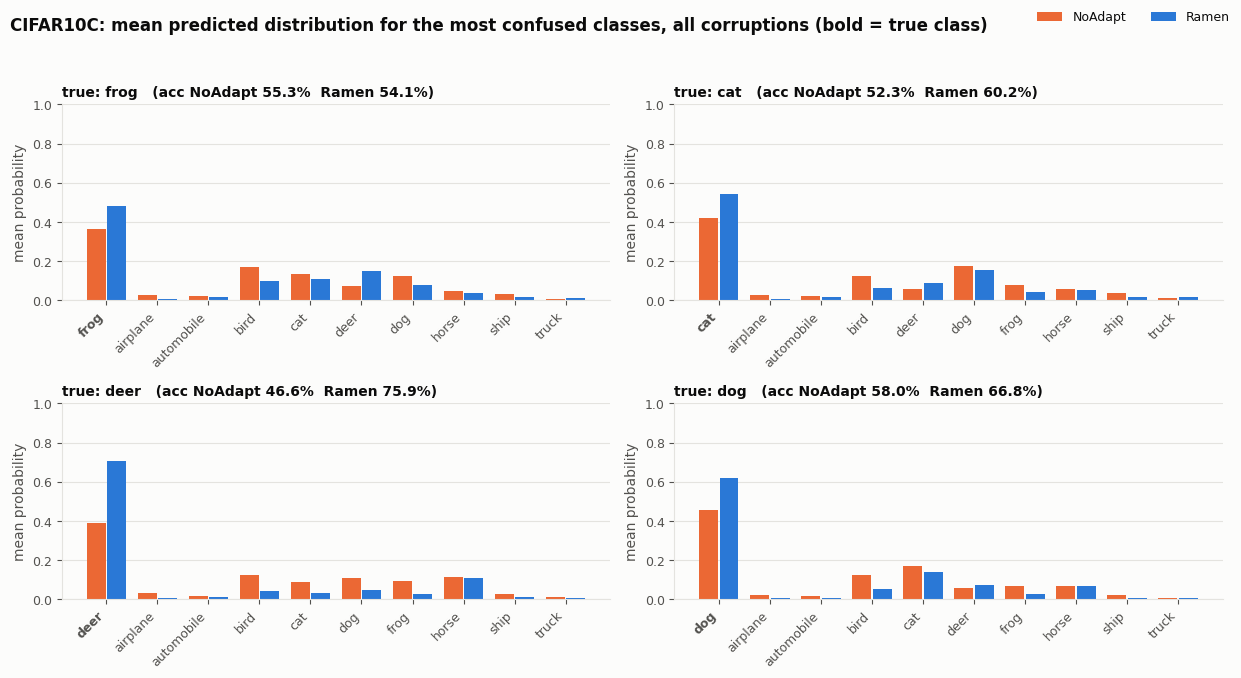

In [5]:
exp.plot_class_probs(n=4);

worst corruption for Ramen: impulse_noise


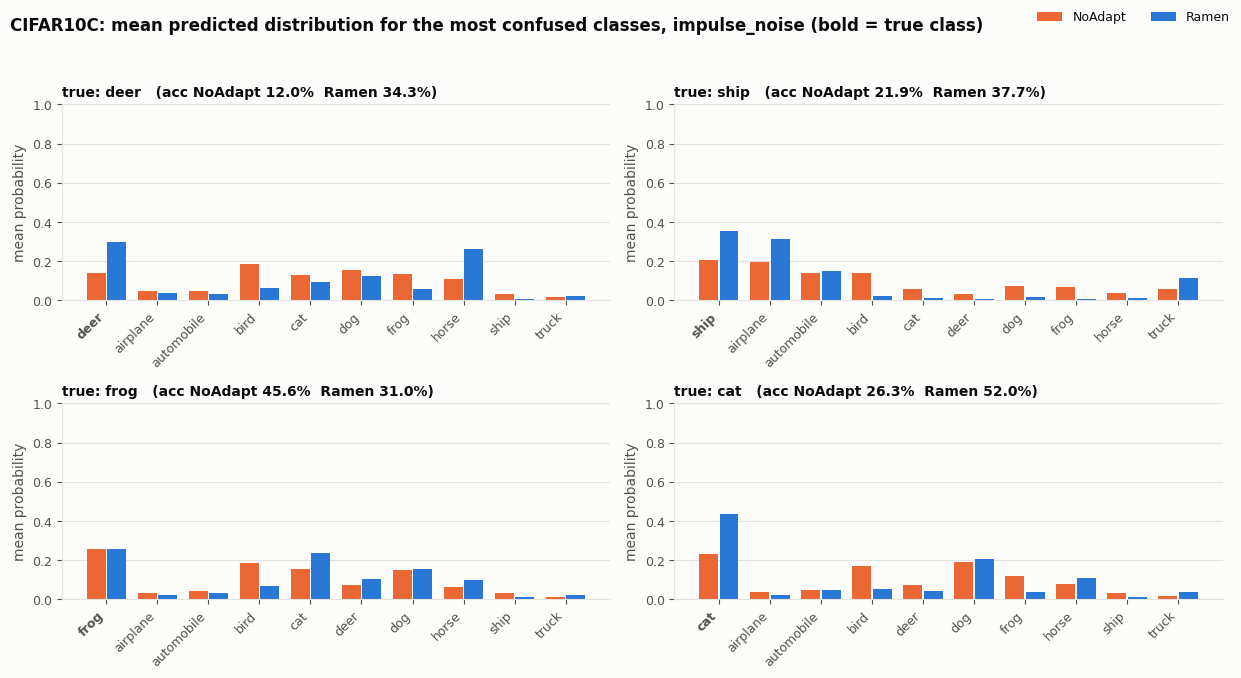

In [6]:
worst = acc.drop('average')['Ramen'].idxmin()
print('worst corruption for Ramen:', worst)
exp.plot_class_probs(domain=worst, n=4);

## 3. True class vs its confuser, per sample
The mean hides the spread. For each top confused pair (A → B), this is a histogram of `p(A) − p(B)` over the samples of true class A. Mass near 0 means the model is torn between the two. Mass far below 0 means it is confidently wrong.

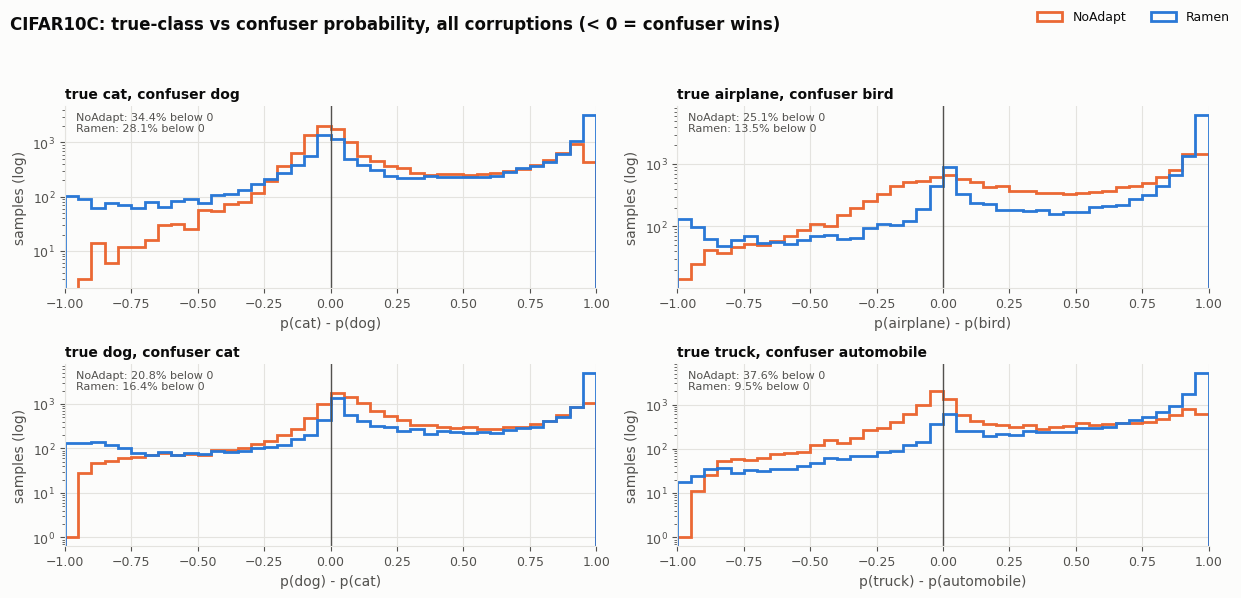

In [7]:
exp.plot_confusion_margin(top_k=4);

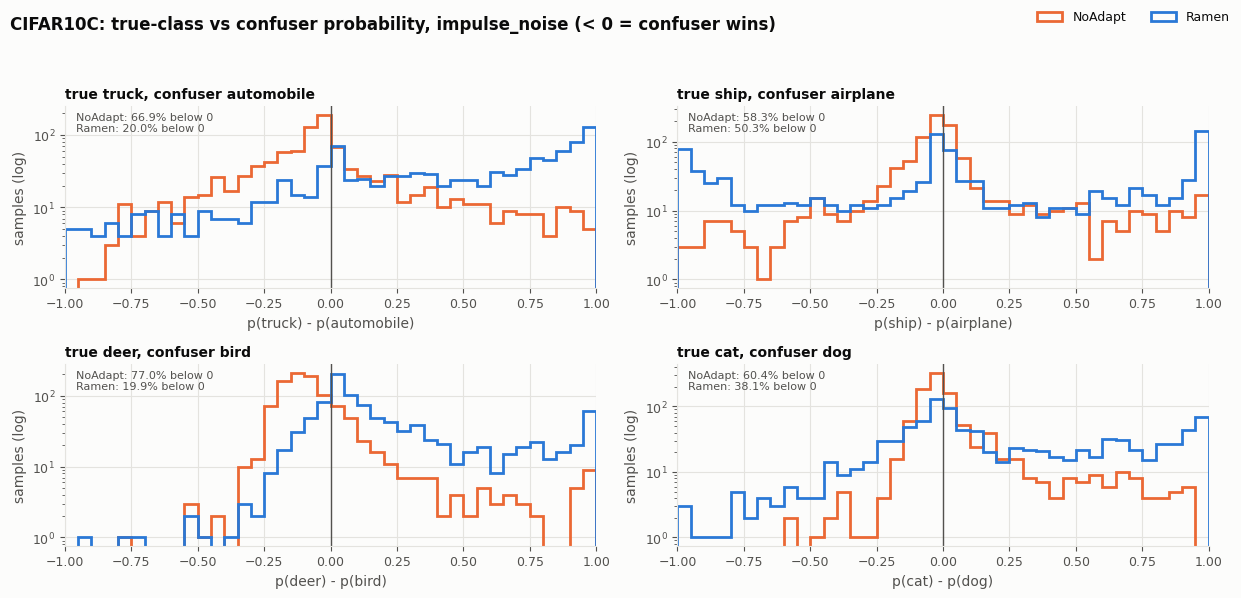

In [8]:
exp.plot_confusion_margin(domain=worst, top_k=4);

## 4. One failed image
A single test image next to both methods' full probability distribution. By default `pick_failure` takes the top confused pair, keeps samples that NoAdapt got right but Ramen got wrong (`kind='broken'`), and returns the one Ramen is most confident on. Use `pair=('frog', 'deer')`, `kind='wrong'`, `domain=...` or `rank=1, 2, ...` to look at others.

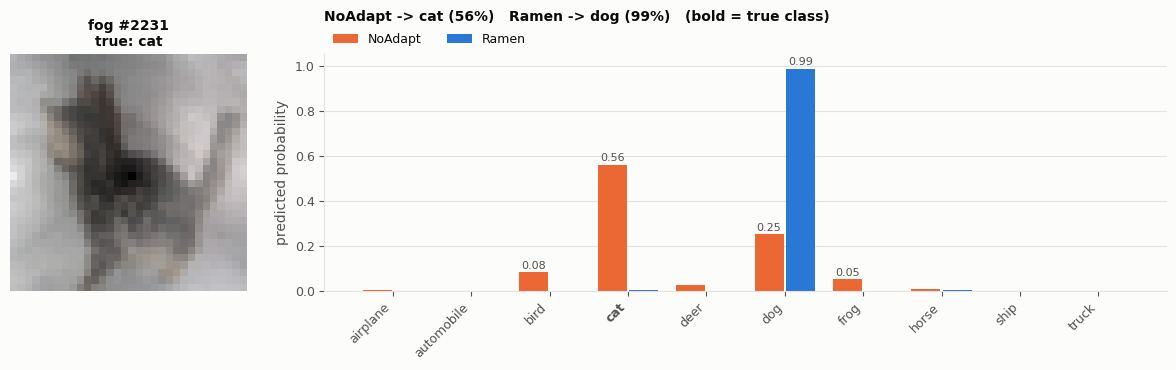

In [9]:
d_idx, s_idx = exp.pick_failure()   # e.g. exp.pick_failure(pair=('frog', 'deer'), rank=0)
exp.plot_sample_probs(d_idx, s_idx);